# CSET485 Assignment 1 – COMPAS (Roll no. 1091, random_state = 91)

In [20]:
%pip install numpy pandas scikit-learn statsmodels matplotlib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 0: Import libraries and set random seed

In [21]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

SEED = 91   # last 3 digits of roll number 1091

## Step 1: Load the COMPAS data and clean it (missing values and filtering)

In [22]:
url = "https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv"
raw = pd.read_csv(url)
print("raw rows:", len(raw))

# standard ProPublica filtering rules
df = raw[(raw.days_b_screening_arrest <= 30) &
         (raw.days_b_screening_arrest >= -30) &
         (raw.is_recid != -1) &
         (raw.c_charge_degree != "O") &
         (raw.score_text != "N/A")].copy().reset_index(drop=True)
print("clean rows:", len(df))

raw rows: 7214
clean rows: 6172


## Step 2: Encode categorical variables and define features 

In [23]:
df["male"] = (df.sex == "Male").astype(int)
df["felony"] = (df.c_charge_degree == "F").astype(int)
for r in ["African-American", "Hispanic", "Other", "Asian", "Native American"]:
    df["race_" + r] = (df.race == r).astype(int)      # Caucasian = reference group
df["y"] = df.two_year_recid                            # this is is_recidivist

cont = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"]
feats = cont + ["male", "felony", "race_African-American", "race_Hispanic",
                "race_Other", "race_Asian", "race_Native American"]
print("missing values in features:", df[feats].isna().sum().sum())

missing values in features: 0


## Step 3: Train/test split, outlier handling and feature scaling 

In [24]:
train, test = train_test_split(df, test_size=0.30, random_state=SEED)
print(len(train), len(test))

# outlier limits come from TRAIN only
low = train[cont].quantile(0.01)
high = train[cont].quantile(0.99)

def prepare(d, scaler=None):
    X = d[feats].astype(float).copy()
    X[cont] = X[cont].clip(low, high, axis=1)          # winsorize outliers
    if scaler is None:
        scaler = StandardScaler().fit(X[cont])         # fit scaler on train
    X[cont] = scaler.transform(X[cont])
    return X, scaler

X_train, scaler = prepare(train)
X_test, _ = prepare(test, scaler)

4320 1852


## Part 1: Model A (OLS) vs Model B (Logistic Regression) 

In [25]:
# Model A: linear regression on decile_score, then threshold at the median
ols = LinearRegression().fit(X_train, train.decile_score)
pred_a = ols.predict(X_test)
median_a = np.median(pred_a)
flag_a = (pred_a >= median_a).astype(int)

# Model B: logistic regression on is_recidivist, threshold at 0.5
logit = LogisticRegression(C=1e6, max_iter=5000).fit(X_train, train.y)   # C large = no regularisation
prob_b = logit.predict_proba(X_test)[:, 1]
flag_b = (prob_b >= 0.5).astype(int)

print("median of OLS predictions:", round(median_a, 3))
cm = confusion_matrix(flag_a, flag_b)
print(pd.DataFrame(cm, index=["A low", "A high"], columns=["B low", "B high"]))

mismatch = (flag_a != flag_b).sum()
print("mismatch:", mismatch, "=", round(100 * mismatch / len(test), 2), "%")
print("A flags high:", flag_a.sum(), "| B flags high:", flag_b.sum())
print("mean prob B:", round(prob_b.mean(), 3), "| accuracy B:", round(accuracy_score(test.y, flag_b), 3))
print("corr(A,B):", round(np.corrcoef(pred_a, prob_b)[0, 1], 3))

median of OLS predictions: 4.41
        B low  B high
A low     915      10
A high    275     652
mismatch: 285 = 15.39 %
A flags high: 927 | B flags high: 662
mean prob B: 0.454 | accuracy B: 0.677
corr(A,B): 0.955


## Part 2.1: Simpson's paradox hunt (split by sex) 

In [26]:
def fit_logit(d, cols):
    X = sm.add_constant(d[cols].astype(float))
    return sm.Logit(d.y, X).fit(disp=0)

cols21 = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count",
          "felony", "race_African-American", "race_Hispanic", "race_Other"]

m_full = fit_logit(df, cols21)
m_men = fit_logit(df[df.male == 1], cols21)       # subgroup A
m_women = fit_logit(df[df.male == 0], cols21)     # subgroup B

key = "race_African-American"
for name, m in [("full", m_full), ("men", m_men), ("women", m_women)]:
    lo, hi = m.conf_int().loc[key]
    print(name, "coef =", round(m.params[key], 3),
          "CI [", round(lo, 3), ",", round(hi, 3), "] p =", round(m.pvalues[key], 4))

# is the men-vs-women difference significant? use an interaction term
d2 = df.copy()
d2["aa_x_male"] = d2["race_African-American"] * d2.male
m_int = fit_logit(d2, cols21 + ["male", "aa_x_male"])
print("interaction coef:", round(m_int.params["aa_x_male"], 3), "p =", round(m_int.pvalues["aa_x_male"], 4))

full coef = 0.081 CI [ -0.042 , 0.204 ] p = 0.1979
men coef = 0.17 CI [ 0.032 , 0.307 ] p = 0.0157
women coef = -0.318 CI [ -0.603 , -0.033 ] p = 0.0286
interaction coef: 0.371 p = 0.0097


## Part 2.2: Omitted-variable bias (drop priors_count) 

In [27]:
cols22 = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count", "male",
          "felony", "race_African-American", "race_Hispanic", "race_Other", "race_Asian", "race_Native American"]

full = fit_logit(df, cols22)
reduced = fit_logit(df, [c for c in cols22 if c != "priors_count"])

table = pd.DataFrame({"full": full.params, "reduced": reduced.params}).drop(["const", "priors_count"])
table["abs_change"] = table.reduced - table.full
table["pct_change"] = 100 * table.abs_change / table.full.abs()
print(table.round(3))

                        full  reduced  abs_change  pct_change
age                   -0.043   -0.026       0.017      38.572
felony                 0.222    0.381       0.159      71.697
juv_fel_count          0.068    0.398       0.330     483.356
juv_misd_count        -0.013    0.353       0.366    2876.970
juv_other_count        0.271    0.374       0.103      38.138
male                   0.334    0.451       0.117      34.926
race_African-American  0.063    0.313       0.250     394.304
race_Asian            -0.529   -0.657      -0.128     -24.207
race_Hispanic         -0.174   -0.165       0.009       5.185
race_Native American  -0.353   -0.021       0.332      93.956
race_Other            -0.159   -0.216      -0.057     -36.094


## Part 2.3: Adversarial subset (confident wrong predictions) 

In [28]:
te = test.copy()
te["p"] = prob_b      # predicted probability from Model B

wrong = te[((te.p >= 0.75) & (te.y == 0)) | ((te.p <= 0.25) & (te.y == 1))]
print("confident wrong:", len(wrong), "=", round(100 * len(wrong) / len(te), 2), "%")

sample = wrong if len(wrong) <= 50 else wrong.sample(50, random_state=SEED)

def summary(d):
    return pd.Series({"mean age": d.age.mean(),
                      "% over 45": 100 * (d.age > 45).mean(),
                      "% male": 100 * d.male.mean(),
                      "% African-American": 100 * (d.race == "African-American").mean(),
                      "mean priors": d.priors_count.mean(),
                      "% zero priors": 100 * (d.priors_count == 0).mean(),
                      "% felony": 100 * d.felony.mean(),
                      "% recidivated": 100 * d.y.mean()})

print(pd.DataFrame({"adversarial 50": summary(sample), "full test": summary(te)}).round(1))

# common trait: old with few priors OR many priors
extreme = ((sample.age > 45) & (sample.priors_count <= 2)) | (sample.priors_count >= 5)
print("% of the 50 at the extremes:", 100 * extreme.mean())

confident wrong: 71 = 3.83 %
                    adversarial 50  full test
mean age                      46.0       34.5
% over 45                     66.0       19.5
% male                        78.0       81.6
% African-American            38.0       52.5
mean priors                    4.7        3.2
% zero priors                 38.0       33.6
% felony                      56.0       65.0
% recidivated                 68.0       45.2
% of the 50 at the extremes: 90.0


## Part 2.4: Fairness trade-off analysis (African-American vs Caucasian) 

      t     DP     EO     PP  accuracy
0  0.05  1.000  1.000  1.371     0.470
1  0.15  1.048  1.018  1.331     0.487
2  0.25  1.171  1.088  1.273     0.546
3  0.35  1.391  1.213  1.195     0.609
4  0.45  1.748  1.489  1.167     0.672
5  0.55  2.267  1.768  1.225     0.675
6  0.65  2.626  1.836  1.179     0.639
7  0.75  4.335  2.410  1.176     0.597
8  0.85  3.854  2.410  1.065     0.567
9  0.95  5.574  4.067  1.000     0.537


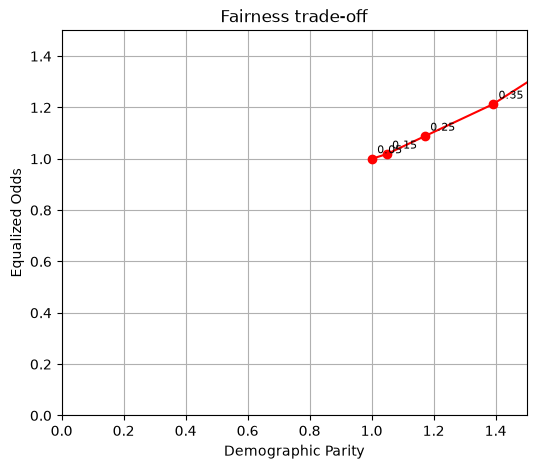

In [29]:
sub = te[te.race.isin(["African-American", "Caucasian"])]
A = sub[sub.race == "African-American"]
B = sub[sub.race == "Caucasian"]

def rates(g, t):
    pred = (g.p >= t).astype(int)
    tp = ((pred == 1) & (g.y == 1)).sum()
    fp = ((pred == 1) & (g.y == 0)).sum()
    return {"sel": pred.mean(),
            "tpr": tp / (g.y == 1).sum(),
            "fpr": fp / (g.y == 0).sum(),
            "ppv": tp / (tp + fp) if (tp + fp) > 0 else np.nan}

def ratio(a, b):
    return a / b if b > 0 else np.nan    # avoid dividing by zero

rows = []
for t in np.round(np.arange(0.05, 0.96, 0.10), 2):
    a, b = rates(A, t), rates(B, t)
    dp = ratio(a["sel"], b["sel"])                                          # demographic parity
    eo = np.nanmin([ratio(a["tpr"], b["tpr"]), ratio(a["fpr"], b["fpr"])])  # equalized odds
    pp = ratio(a["ppv"], b["ppv"])                                          # predictive parity
    acc = ((sub.p >= t).astype(int) == sub.y).mean()
    rows.append([t, dp, eo, pp, acc])

sweep = pd.DataFrame(rows, columns=["t", "DP", "EO", "PP", "accuracy"])
print(sweep.round(3))

plt.figure(figsize=(6, 5))
plt.plot(sweep.DP, sweep.EO, "o-", color="red")
for _, r in sweep.iterrows():
    plt.annotate(str(r.t), (r.DP, r.EO), xytext=(4, 4), textcoords="offset points", fontsize=8)
plt.xlim(0, 1.5); plt.ylim(0, 1.5)          # axes as the assignment asks
plt.xlabel("Demographic Parity"); plt.ylabel("Equalized Odds")
plt.title("Fairness trade-off"); plt.grid(True); plt.show()

## Supporting calculations for Part 3 (Q3 and Q5) 

In [30]:
from scipy.stats import chi2

# Q3: how correlated is priors_count with the other predictors?
print(df[["priors_count", "age", "race_African-American", "male", "felony"]].corr().iloc[0].round(2))
print("log-likelihood full:", round(full.llf, 1), "| reduced:", round(reduced.llf, 1))

# Q5: does adding non-linear / interaction terms improve the model? (likelihood-ratio test on train)
tr = train.copy()
tr["age2"] = tr.age ** 2
tr["priors2"] = tr.priors_count ** 2
tr["age_x_priors"] = tr.age * tr.priors_count

m0 = fit_logit(tr, cols22)
m1 = fit_logit(tr, cols22 + ["age2", "priors2", "age_x_priors"])
lr = 2 * (m1.llf - m0.llf)
print("LR stat:", round(lr, 1), "| p-value:", chi2.sf(lr, 3))
print("AIC before:", round(m0.aic), "after:", round(m1.aic))
print(m1.params[["age2", "priors2", "age_x_priors"]].round(5))

# Q5: calibration for older defendants with few priors
old_low = te[(te.age > 45) & (te.priors_count <= 2)]
print("n:", len(old_low), "| mean predicted:", round(old_low.p.mean(), 3), "| actual rate:", round(old_low.y.mean(), 3))

priors_count             1.00
age                      0.12
race_African-American    0.22
male                     0.12
felony                   0.15
Name: priors_count, dtype: float64
log-likelihood full: -3752.0 | reduced: -3993.0
LR stat: 77.3 | p-value: 1.1843070327547646e-16
AIC before: 5299 after: 5228
age2            0.00129
priors2        -0.00632
age_x_priors   -0.00113
dtype: float64
n: 218 | mean predicted: 0.185 | actual rate: 0.229


## Supporting calculations for Q1 (Part 1 numbers) 

In [31]:
print("OLS test R2:", round(ols.score(X_test, test.decile_score), 3))
print("OLS predictions outside 1-10:", ((pred_a < 1) | (pred_a > 10)).sum())
print("% of people with prob < 0.5:", round(100 * (prob_b < 0.5).mean(), 1))
print("A-only high:", ((flag_a == 1) & (flag_b == 0)).sum(), "| B-only high:", ((flag_a == 0) & (flag_b == 1)).sum())
print("% flagged high: A =", round(100 * flag_a.mean(), 2), "| B =", round(100 * flag_b.mean(), 2))
print("actual recidivism rate in test:", round(100 * test.y.mean(), 1), "%")
print("recidivism rate among the mismatched people:", round(100 * test.y.values[flag_a != flag_b].mean(), 1), "%")
print("accuracy of A's rule vs truth:", round(accuracy_score(test.y, flag_a), 3))

OLS test R2: 0.442
OLS predictions outside 1-10: 84
% of people with prob < 0.5: 64.3
A-only high: 275 | B-only high: 10
% flagged high: A = 50.05 | B = 35.75
actual recidivism rate in test: 45.2 %
recidivism rate among the mismatched people: 39.6 %
accuracy of A's rule vs truth: 0.65


## Supporting calculations for Q2 (Part 2.1 numbers) 

In [32]:
import math
for g, d in [("men", df[df.male == 1]), ("women", df[df.male == 0])]:
    aa = d[d.race == "African-American"]; ca = d[d.race == "Caucasian"]
    print(g, "n =", len(d), "| recid rate AA:", round(100 * aa.y.mean(), 1), "Cauc:", round(100 * ca.y.mean(), 1),
          "| mean priors AA:", round(aa.priors_count.mean(), 2), "Cauc:", round(ca.priors_count.mean(), 2))
for name, m in [("men", m_men), ("women", m_women)]:
    print(name, "odds ratio for African-American:", round(math.exp(m.params[key]), 2))
b1, b2 = m_men.params[key], m_women.params[key]
s1, s2 = m_men.bse[key], m_women.bse[key]
print("z for men vs women difference:", round((b1 - b2) / math.sqrt(s1**2 + s2**2), 2))
for v in ["priors_count", "age", "felony"]:
    print(v, "men:", round(m_men.params[v], 3), "women:", round(m_women.params[v], 3), "full:", round(m_full.params[v], 3))

men n = 4997 | recid rate AA: 55.5 Cauc: 40.2 | mean priors AA: 4.59 Cauc: 2.43
women n = 1175 | recid rate AA: 37.0 Cauc: 35.3 | mean priors AA: 2.53 Cauc: 1.81
men odds ratio for African-American: 1.18
women odds ratio for African-American: 0.73
z for men vs women difference: 3.02
priors_count men: 0.15 women: 0.225 full: 0.162
age men: -0.044 women: -0.036 full: -0.043
felony men: 0.168 women: 0.413 full: 0.232


## Supporting calculations for Q5 (Part 2.3 numbers) 

In [33]:
print("confident false positives:", ((te.p >= 0.75) & (te.y == 0)).sum(), "of", (te.p >= 0.75).sum(), "confident positives")
print("confident false negatives:", ((te.p <= 0.25) & (te.y == 1)).sum(), "of", (te.p <= 0.25).sum(), "confident negatives")
print("false negatives in the 50:", (sample.y == 1).sum(), "| false positives in the 50:", (sample.y == 0).sum())
print("FN in sample who are old with <=2 priors (%):", round(100 * ((sample[sample.y == 1].age > 45) & (sample[sample.y == 1].priors_count <= 2)).mean(), 1))
print("FP in sample with 5+ priors (%):", round(100 * (sample[sample.y == 0].priors_count >= 5).mean(), 1))

confident false positives: 19 of 147 confident positives
confident false negatives: 52 of 261 confident negatives
false negatives in the 50: 34 | false positives in the 50: 16
FN in sample who are old with <=2 priors (%): 85.3
FP in sample with 5+ priors (%): 100.0


## Supporting calculations for Q6–Q8 (Part 2.4 numbers) 

In [34]:
detail = []
for t in np.round(np.arange(0.05, 0.96, 0.10), 2):
    a, b = rates(A, t), rates(B, t)
    detail.append([t, a["sel"], b["sel"], a["tpr"], b["tpr"], a["fpr"], b["fpr"], a["ppv"], b["ppv"]])
detail = pd.DataFrame(detail, columns=["t", "selA", "selB", "tprA", "tprB", "fprA", "fprB", "ppvA", "ppvB"])
print(detail.round(3))
print("base rate A:", round(A.y.mean(), 3), "| base rate B:", round(B.y.mean(), 3))

s = sweep.set_index("t")
dp_gain = 1 - abs(s.loc[0.25, "DP"] - 1) / abs(s.loc[0.45, "DP"] - 1)
pp_loss = abs(s.loc[0.25, "PP"] - 1) / abs(s.loc[0.45, "PP"] - 1) - 1
print("t=0.45 -> t=0.25: DP gap closes by", round(100 * dp_gain), "% | PP gap grows by", round(100 * pp_loss), "% | cost =", round(pp_loss / dp_gain, 2))
print("accuracy:", round(s.loc[0.45, "accuracy"], 3), "->", round(s.loc[0.25, "accuracy"], 3))

      t   selA   selB   tprA   tprB   fprA   fprB   ppvA   ppvB
0  0.05  1.000  1.000  1.000  1.000  1.000  1.000  0.524  0.382
1  0.15  0.991  0.945  0.996  0.978  0.985  0.925  0.526  0.395
2  0.25  0.928  0.792  0.974  0.896  0.877  0.728  0.550  0.432
3  0.35  0.825  0.593  0.917  0.757  0.724  0.492  0.582  0.487
4  0.45  0.607  0.347  0.770  0.517  0.428  0.242  0.664  0.569
5  0.55  0.365  0.161  0.546  0.270  0.166  0.094  0.783  0.639
6  0.65  0.218  0.083  0.354  0.157  0.069  0.038  0.849  0.720
7  0.75  0.122  0.028  0.210  0.057  0.026  0.011  0.899  0.765
8  0.85  0.058  0.015  0.104  0.035  0.006  0.003  0.946  0.889
9  0.95  0.009  0.002  0.018  0.004  0.000  0.000  1.000  1.000
base rate A: 0.524 | base rate B: 0.382
t=0.45 -> t=0.25: DP gap closes by 77 % | PP gap grows by 64 % | cost = 0.83
accuracy: 0.672 -> 0.546
